In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import nibabel as nib
import os
from datetime import datetime, timedelta
from scipy.ndimage import map_coordinates, gaussian_filter

# Configurations
N_SUBJECTS = 100
VOLUME_SIZE = (32, 32, 32)
TIMEPOINTS = [0, 6, 12, 18, 24, 30, 36]
VISITS = ['sc', 'm06', 'm12', 'm18', 'm24', 'm30', 'm36']
GROUPS = ['CN', 'MCI', 'AD']
BASE_DATE = datetime(2007, 8, 24)
OUTPUT_DIR = "/scratch/anirudhkaushik/ToyBrainDataset/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

AGES = np.random.randint(50, 81, N_SUBJECTS)
AGE_VENTRICLE_SCALING = 0.1
EPSILON = 1e-3
metadata = []

def create_ellipsoid(center, radii, volume_shape):
    grid = np.indices(volume_shape).transpose(1, 2, 3, 0)
    norm = ((grid - center) / radii) ** 2
    return np.sum(norm, axis=-1) <= 1

def limit_ventricle_size(ventricle_radii, brain_radii):
    return np.minimum(ventricle_radii, brain_radii - EPSILON)

def apply_intensity_variation(volume):
    noise = np.random.normal(loc=0, scale=5, size=volume.shape)
    bias_field = np.linspace(0.9, 1.1, volume.shape[0]).reshape(-1, 1, 1)
    volume = volume * bias_field + noise
    return np.clip(volume, 0, 255).astype(np.uint8)

def apply_diffeomorphic_deformation(volume, alpha=1.5, sigma=8):
    random_field = np.random.normal(size=volume.shape + (3,))
    for i in range(3):
        random_field[..., i] = gaussian_filter(random_field[..., i], sigma=sigma) * alpha
    grid = np.indices(volume.shape).transpose(1, 2, 3, 0).astype(np.float32)
    deformed_grid = grid + random_field
    deformed = map_coordinates(volume, [deformed_grid[..., i] for i in range(3)], order=1, mode='reflect')
    return deformed

def create_brain(subject_id, time, base_radii, age, group, base_region_radii):
    brain = np.zeros(VOLUME_SIZE, dtype=np.uint8)
    center = np.array(VOLUME_SIZE) // 2
    brain_mask = create_ellipsoid(center, base_radii, VOLUME_SIZE)
    age_factor = 1 + (((age - 30)/2) * (AGE_VENTRICLE_SCALING / 2))

    group_atrophy_rates = {
        'CN': [0.03, 0.05],
        'MCI': [0.1, 0.2],
        'AD': [0.2, 0.3]
    }
    region_velocities = group_atrophy_rates[group]
    offsets = [(-5, 0, 0), (5, 0, 0)]

    for i, offset in enumerate(offsets):
        velocity_noise = np.random.normal(0, 0.001)
        acceleration_noise = np.random.normal(0, 0.0005)
        velocity = region_velocities[i] + velocity_noise
        acceleration = velocity * 0.1 + acceleration_noise

        time_years = time / 12.0
        growth = 1 + (velocity * time_years + 0.5 * acceleration * (time_years ** 2)) * 0.5
        region_radii = base_region_radii[i] * age_factor * growth
        region_radii = limit_ventricle_size(region_radii, base_radii / 2)
        region_center = center + np.array(offset)
        region_mask = create_ellipsoid(region_center, region_radii, VOLUME_SIZE)
        brain_mask &= ~region_mask

    brain[brain_mask] = np.random.randint(80, 120)
    brain = apply_diffeomorphic_deformation(brain)
    brain = apply_intensity_variation(brain)
    return brain

def generate_image_id():
    return f"I{random.randint(100000, 999999)}"

brains = []
subject_groups = []
for subject_id in range(N_SUBJECTS):
    age = AGES[subject_id]
    base_radii = np.random.uniform(12, 15, size=3)
    group = np.random.choice(GROUPS)
    subject_groups.append(group)
    subj_name = f"S{str(subject_id).zfill(4)}"

    subject_scans = []
    base_region_radii = [
        np.array([random.uniform(1.8, 2.2), random.uniform(1.3, 1.7), random.uniform(3.8, 4.2)]),
        np.array([random.uniform(1.8, 2.2), random.uniform(1.3, 1.7), random.uniform(3.8, 4.2)])
    ]

    for idx, time in enumerate(TIMEPOINTS):
        brain = create_brain(subject_id, time, base_radii, age, group, base_region_radii)
        subject_scans.append(brain)
        image_id = generate_image_id()
        visit = VISITS[idx]
        acq_date = BASE_DATE + timedelta(days=30*time)
        filename = f"{image_id}.nii.gz"
        file_path = os.path.join(OUTPUT_DIR, filename)
        nib.save(nib.Nifti1Image(brain, np.eye(4)), file_path)

        metadata.append([
            image_id, subj_name, group, age, visit, "MRI",
            "MPR; GradWarp; B1 Correction; N3; Scaled", "Processed",
            acq_date.strftime("%m/%d/%Y"), "NiFTI", datetime.now().strftime("%m/%d/%Y"), file_path
        ])
    brains.append(subject_scans)

columns = ["Image Data ID", "Subject", "Group", "Age", "Visit", "Modality",
           "Description", "Type", "Acq Date", "Format", "Downloaded", "File_Path"]
pd.DataFrame(metadata, columns=columns).to_csv("metadata.csv", index=False)

def show_brain_views(subject_scans, subject_id, age, group):
    fig, axes = plt.subplots(3, len(TIMEPOINTS), figsize=(15, 10))
    view_names = ['Axial', 'Coronal', 'Sagittal']
    for row, view in enumerate(view_names):
        for col, time_idx in enumerate(range(len(TIMEPOINTS))):
            brain = subject_scans[time_idx]
            if view == 'Axial':
                slice_img = brain[:, :, VOLUME_SIZE[2] // 2]
            elif view == 'Coronal':
                slice_img = brain[:, VOLUME_SIZE[1] // 2, :]
            else:
                slice_img = brain[VOLUME_SIZE[0] // 2, :, :]
            axes[row, col].imshow(slice_img.T, cmap='gray', origin='lower')
            if row == 0:
                axes[row, col].set_title(f"Month {TIMEPOINTS[time_idx]}", fontsize=12)
        axes[row, 0].set_ylabel(f"{view} View", fontsize=14, rotation=90, labelpad=10)
    fig.suptitle(f"Subject {subject_id} (Age {age}, Group {group}) Brain Morphology Over Time", fontsize=18)
    plt.tight_layout(rect=[0.05, 0.05, 1, 0.95])
    plt.show()




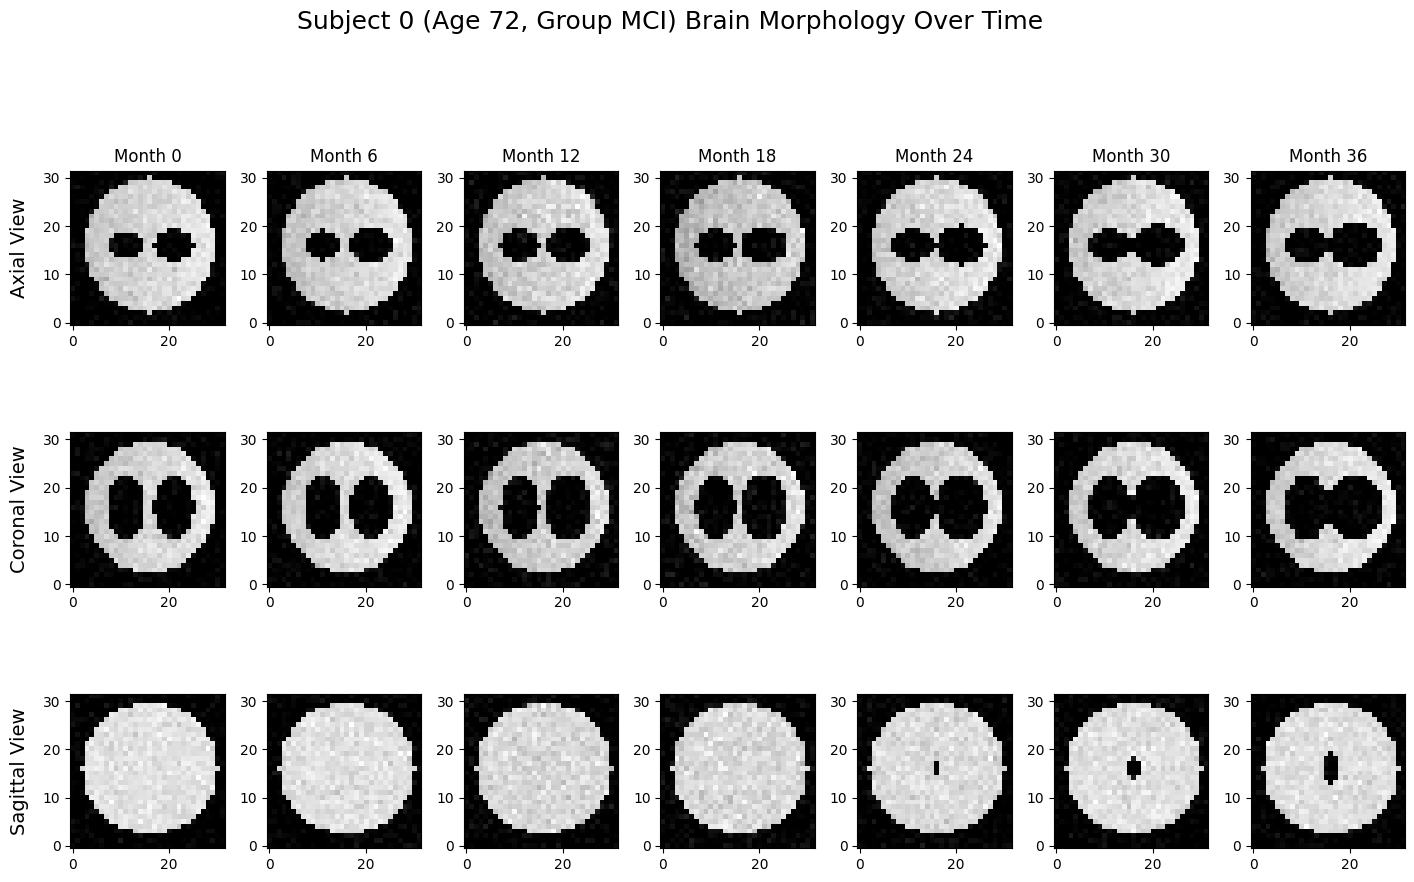

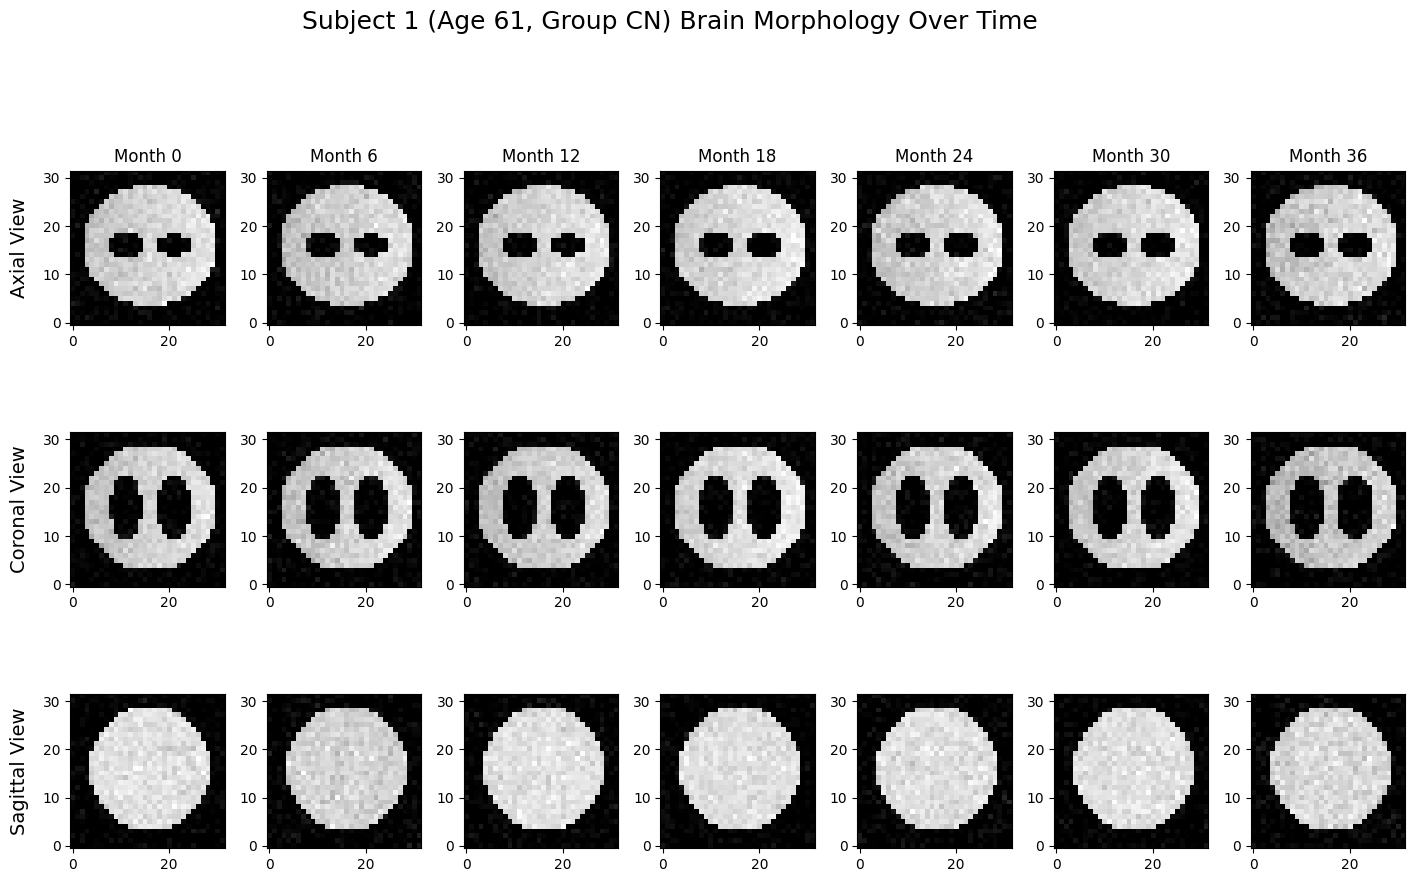

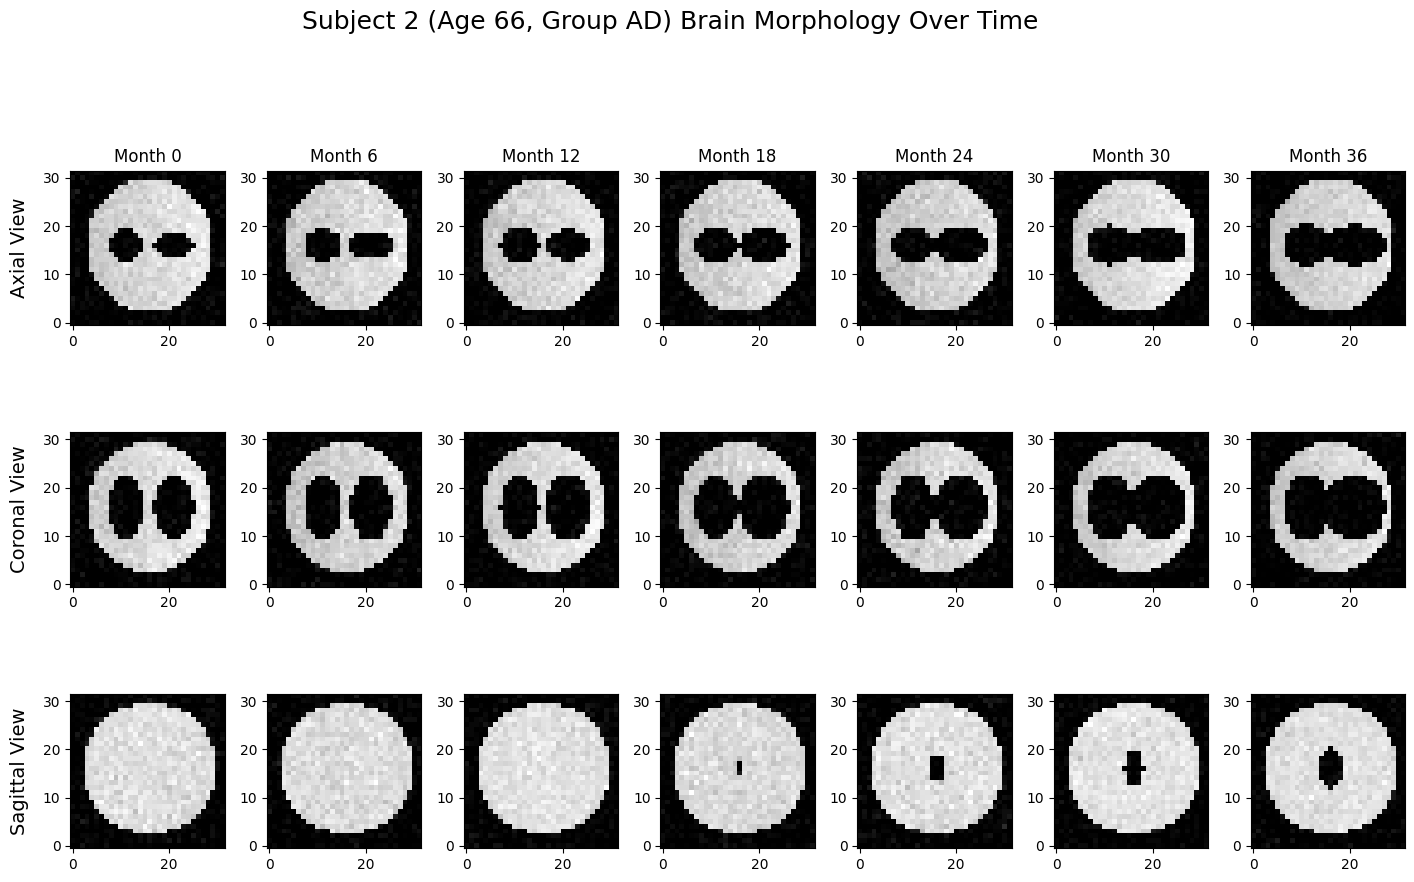

In [20]:
show_brain_views(brains[0], 0, AGES[0], subject_groups[0])
show_brain_views(brains[1], 1, AGES[1], subject_groups[1])
show_brain_views(brains[2], 2, AGES[2], subject_groups[2])


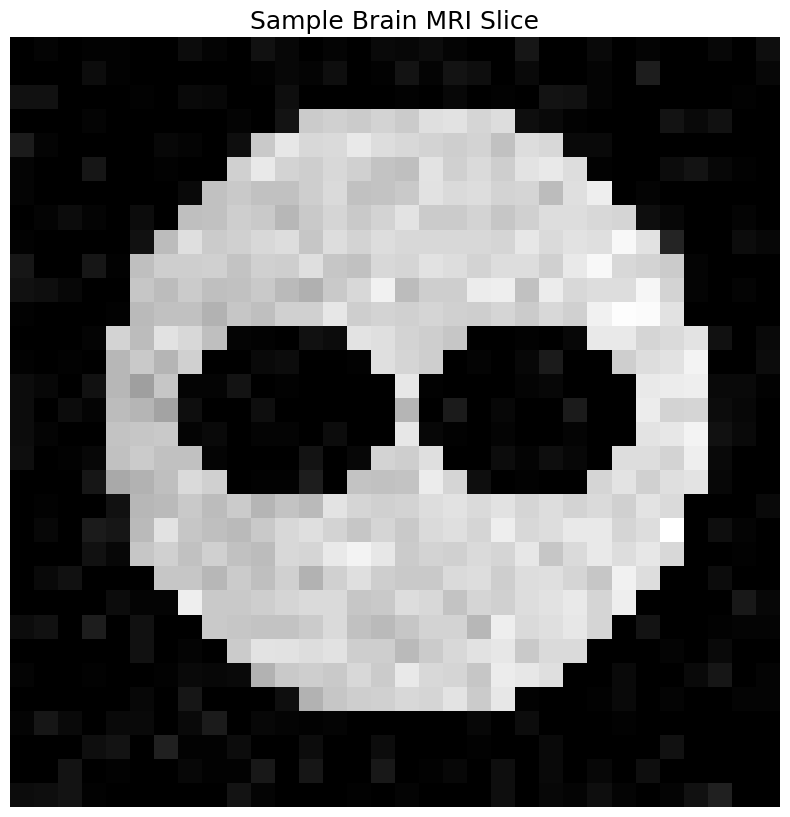

In [27]:
loaded_img = nib.load("/scratch/anirudhkaushik/ToyBrainDataset/I892361.nii.gz")
img_data = loaded_img.get_fdata()

plt.figure(figsize=(10, 10))
plt.imshow(img_data[:, :, 16].T, cmap='gray', origin='lower')
plt.title("Sample Brain MRI Slice", fontsize=18)
plt.axis('off')
plt.show()